# ESC-10 Sound Classifier: model creation, evaluation and retraining
**Task:** classify a 5-second environmental sound clip into one of 10 classes (dog, rooster, rain, sea waves, crackling fire, crying baby, helicopter, chainsaw, clock tick, sneezing).

**Pipeline covered here:** 1. Data acquisition → 2. Data processing → 3. Model creation → 4. Model testing → 5. Retraining (trigger) → production-style evaluation through the API.
The same code (`src/`) powers the FastAPI service, the dashboard and the Docker deployment.

In [1]:
import os, sys, pickle, tempfile, shutil, subprocess, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Work on a temporary copy so running the notebook never overwrites the repo's model/data
WORK = Path(tempfile.mkdtemp())
shutil.copytree(ROOT / "data", WORK / "data"); (WORK / "models").mkdir()
os.environ.update(DATA_DIR=str(WORK / "data"), MODEL_DIR=str(WORK / "models"), AUTO_RETRAIN_THRESHOLD="20")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa, librosa.display, soundfile as sf
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             confusion_matrix, classification_report, roc_auc_score)
from src import train as T
from src.features import FEATURE_NAMES, SR, load_audio, extract_features
plt.rcParams["figure.dpi"] = 110

## 1. Data acquisition
ESC-10 is a labelled subset of the public [ESC-50](https://github.com/karolpiczak/ESC-50) dataset: 400 clips (40 per class), split into 5 predefined folds. Clips cut from the same original recording share a fold, so using the folds avoids train/test leakage.

In [2]:
ESC_DIR = Path(os.getenv("ESC_DIR", ROOT / "ESC-50"))
if not (ESC_DIR / "audio").exists():          # download only the ESC-10 clips (sparse git checkout, ~150 MB)
    print("Downloading ESC-10 audio...")
    subprocess.run(["git","clone","--depth","1","--filter=blob:none","--sparse","https://github.com/karolpiczak/ESC-50.git",str(ESC_DIR)],check=True)
    meta = pd.read_csv(ESC_DIR/"meta"/"esc50.csv"); e = meta[meta.esc10]
    subprocess.run(["git","-C",str(ESC_DIR),"sparse-checkout","set","--no-cone","/meta/esc50.csv",*["/audio/"+f for f in e.filename]],check=True)
meta = pd.read_csv(ESC_DIR / "meta" / "esc50.csv"); meta = meta[meta.esc10]
print(meta.shape); display(meta.groupby("category").size().to_frame("clips").T)
print("Clips per fold:", meta.fold.value_counts().sort_index().to_dict())

(400, 7)


category,chainsaw,clock_tick,crackling_fire,crying_baby,dog,helicopter,rain,rooster,sea_waves,sneezing
clips,40,40,40,40,40,40,40,40,40,40


Clips per fold: {1: 80, 2: 80, 3: 80, 4: 80, 5: 80}


## 2. Data processing (preprocessing steps)
The raw data is 400 `.wav` clips, which a classical ML model cannot use directly. The preprocessing pipeline is:

1. **Inspect** the raw audio (sample rate, channels, duration, silence, clipping).
2. **Standardise** every clip: resample to 22.05 kHz, convert to mono, cap at 5 s.
3. **Extract features**: summarise each clip into 34 numbers (MFCCs and spectral/energy statistics).
4. **Validate** the feature table: missing values, duplicates, constant columns, outliers, class balance.
5. **Check feature relationships**: correlations between features.
6. **Scale and split**: standardise features (fit on the training data only) and split by the predefined ESC folds.

First, what the raw signals look like:

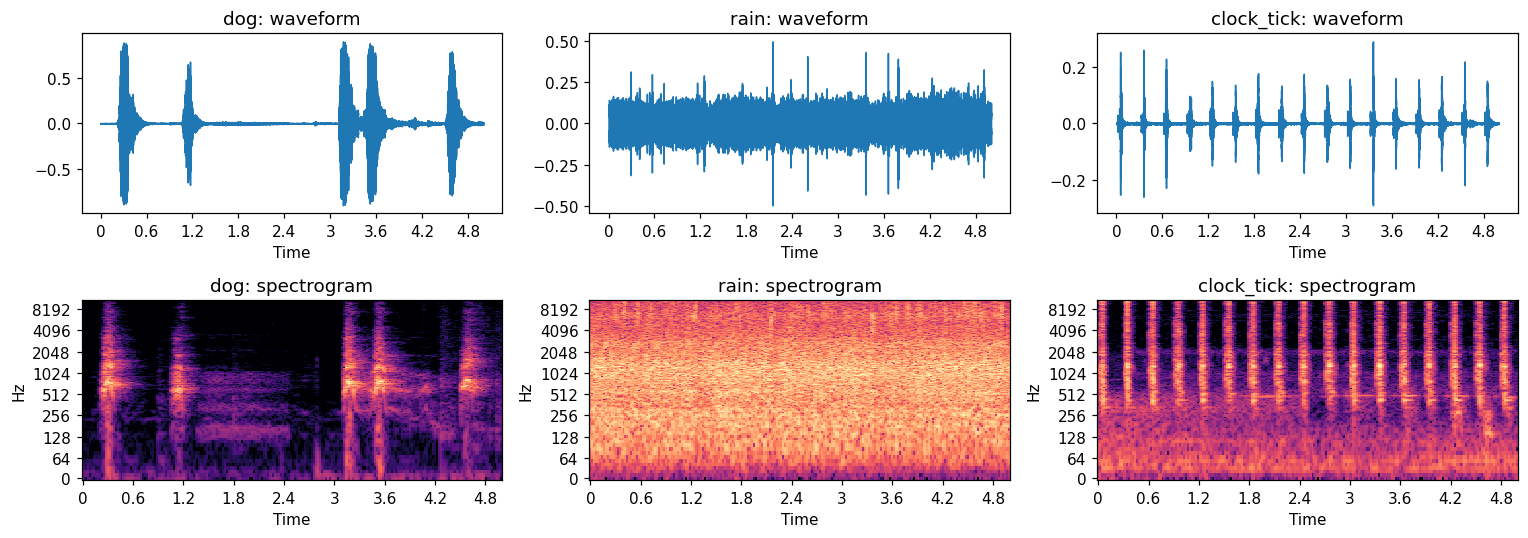

In [3]:
show = ["dog", "rain", "clock_tick"]
fig, ax = plt.subplots(2, 3, figsize=(14, 5))
for i, c in enumerate(show):
    fn = meta[(meta.category == c) & (meta.fold == 5)].filename.iloc[0]
    y = load_audio(ESC_DIR / "audio" / fn)
    librosa.display.waveshow(y, sr=SR, ax=ax[0, i]); ax[0, i].set_title(f"{c}: waveform")
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="log", ax=ax[1, i]); ax[1, i].set_title(f"{c}: spectrogram")
plt.tight_layout(); plt.show()

### 2.1 Audit of the raw audio files
Before touching the signal we check what the files actually contain.

Sample rates: [44100] | channels: [1] | durations (s): [5.]


,count,mean,std,min,25%,50%,75%,max
peak,400.0,0.776,0.222,0.086,0.686,0.857,0.943,1.000
silent_frac,400.0,0.142,0.239,0.000,0.001,0.007,0.184,0.936
clipped_frac,400.0,0.000,0.000,0.000,0.000,0.000,0.000,0.009


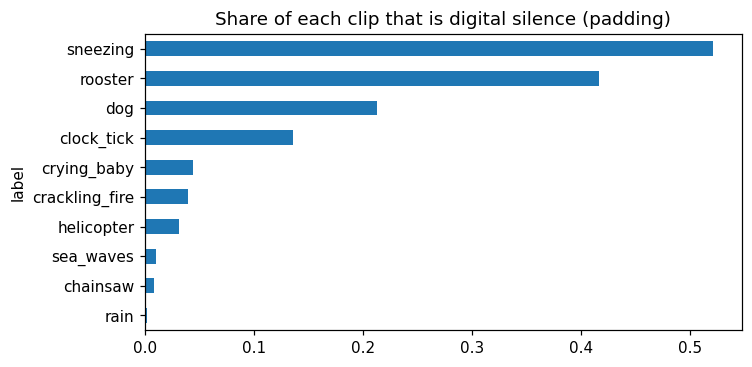

In [4]:
rows = []
for r in meta.itertuples():
    y, sr = librosa.load(ESC_DIR / "audio" / r.filename, sr=None, mono=False)   # raw: original sample rate and channels
    ch = 1 if y.ndim == 1 else y.shape[0]
    y1 = y if y.ndim == 1 else y.mean(axis=0)
    rows.append(dict(label=r.category, fold=r.fold, orig_sr=sr, channels=ch, duration_s=len(y1)/sr,
                     peak=np.abs(y1).max(), silent_frac=(np.abs(y1) < 1e-4).mean(), clipped_frac=(np.abs(y1) >= 0.999).mean()))
audit = pd.DataFrame(rows)
print("Sample rates:", audit.orig_sr.unique(), "| channels:", audit.channels.unique(), "| durations (s):", audit.duration_s.round(2).unique())
display(audit[["peak", "silent_frac", "clipped_frac"]].describe().round(3).T)
audit.groupby("label").silent_frac.mean().sort_values().plot.barh(figsize=(7, 3.5), title="Share of each clip that is digital silence (padding)")
plt.show()

**What the audit tells us:** all files are 44.1 kHz and exactly 5 s long. Many clips are shorter events padded with digital silence (about 52% of the average sneezing clip, 42% of rooster and 21% of dog, but about 0-3% for rain, chainsaw, sea waves and helicopter), so "how much of the clip is silent" is itself informative, and it affects features such as spectral flatness (see the caveat in section 3). 17 of the 400 clips touch full scale, but for under 1% of their samples, so no clips are dropped.

### 2.2 Standardising the signal and extracting features
Each clip goes through the same function in `src/features.py` (the API uses the identical code, so training and serving cannot drift apart):

In [5]:
import inspect
from src import features as F
print(inspect.getsource(F.load_audio)); print(inspect.getsource(F.extract_features))

def load_audio(source):
    """Load a path / bytes / file-like object as mono float audio at SR (max DURATION s)."""
    if isinstance(source, (bytes, bytearray)):
        source = io.BytesIO(source)
    y, _ = librosa.load(source, sr=SR, mono=True, duration=DURATION)
    return y

def extract_features(y, sr=SR):
    """Return a dict {feature_name: value} for one waveform."""
    if len(y) < int(0.5 * sr):
        raise ValueError("Audio is shorter than 0.5 seconds")
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    cen = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    bw = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    roll = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    flat = librosa.feature.spectral_flatness(y=y)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]
    rms = librosa.feature.rms(y=y)[0]
    vals = (list(mfcc.mean(axis=1)) + list(mfcc.std(axis=1))
            + [cen.mean(), cen.std(), bw.mean(), roll.mean(), flat.mean(), zcr.mean(), rm

| Feature group | Count | What it captures |
|---|---|---|
| MFCC 1-13, mean | 13 | Overall spectral *shape* (timbre) of the sound |
| MFCC 1-13, std | 13 | How much that timbre changes over time |
| Spectral centroid mean / std | 2 | "Brightness" of the sound and its variation |
| Spectral bandwidth, roll-off | 2 | How widely energy is spread; frequency below which 85% of energy lies |
| Spectral flatness | 1 | Noise-like (1) vs. tonal (0) |
| Zero-crossing rate | 1 | Rough pitch/noisiness indicator |
| RMS energy mean / std | 2 | Loudness and how bursty it is |

Summarising each clip as means and standard deviations over time turns a variable-length signal into a fixed-length vector (34 numbers) that classical models can use.

### 2.3 Validating the feature table

In [6]:
df = pd.read_csv(ROOT / "data" / "base_features.csv")     # produced by scripts/build_features.py with the same extractor
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
print("Constant (zero-variance) features:", [c for c in FEATURE_NAMES if df[c].nunique() == 1])
z = (df[FEATURE_NAMES] - df[FEATURE_NAMES].mean()) / df[FEATURE_NAMES].std()
print("Extreme values (|z| > 4):", int((z.abs() > 4).sum().sum()), "of", z.size, "cells")
print("Class balance:", df.label.value_counts().unique(), "clips per class | folds:", df.fold.value_counts().sort_index().to_dict())
df[["label","fold"] + FEATURE_NAMES[:4]].head()

Shape: (400, 37) | missing values: 0 | duplicate rows: 0
Constant (zero-variance) features: []
Extreme values (|z| > 4): 36 of 13600 cells
Class balance: [40] clips per class | folds: {1: 80, 2: 80, 3: 80, 4: 80, 5: 80}


,label,fold,mfcc1_mean,mfcc2_mean,mfcc3_mean,mfcc4_mean
0,dog,1,-600.940125,4.694290,-8.505940,-4.276621
1,dog,1,-586.231384,10.243309,-2.999349,-2.870357
2,chainsaw,1,-59.360371,84.921059,-31.395706,5.980680
3,crackling_fire,1,-286.097534,61.970379,19.463919,28.494677
4,helicopter,1,-21.646334,31.408426,55.538555,24.222033


There are no missing values, duplicates or constant features, and the classes are perfectly balanced (40 each), so no imputation, resampling or class weighting is needed. The few extreme values are genuine loud events, not errors, so they are kept (the SVM uses scaled features and is robust to them).

### 2.4 Relationships between features

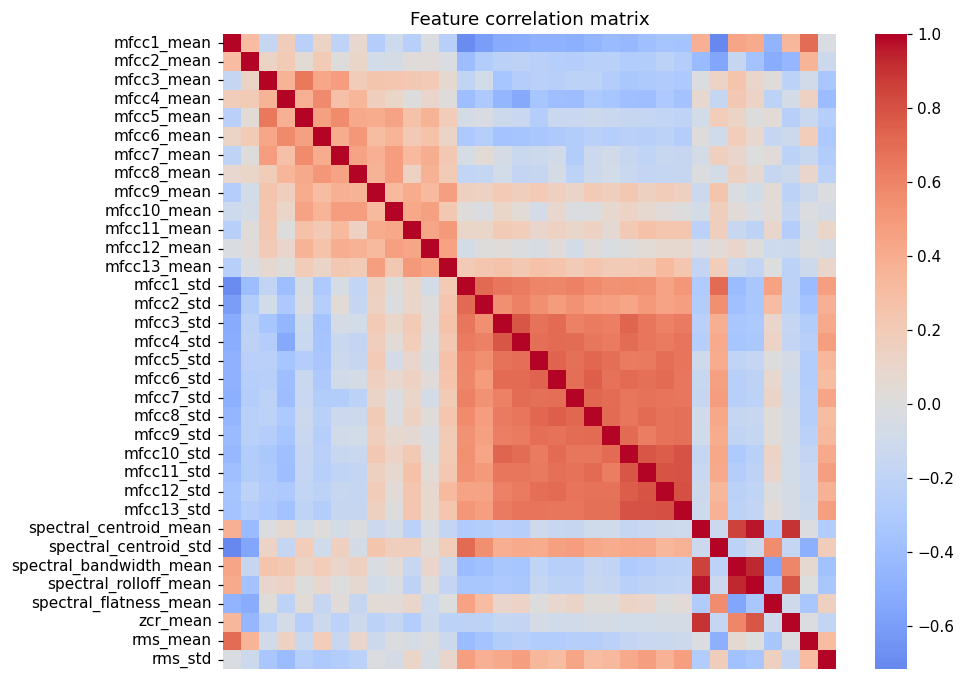

Most correlated pairs:


spectral_centroid_mean   spectral_rolloff_mean      0.964
spectral_bandwidth_mean  spectral_rolloff_mean      0.929
spectral_centroid_mean   zcr_mean                   0.897
                         spectral_bandwidth_mean    0.847
mfcc12_std               mfcc13_std                 0.805
mfcc11_std               mfcc13_std                 0.797
dtype: float64

In [7]:
corr = df[FEATURE_NAMES].corr()
plt.figure(figsize=(9, 7.5)); sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False); plt.title("Feature correlation matrix"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().abs().sort_values(ascending=False)
print("Most correlated pairs:"); display(pairs.head(6).round(3))

The spectral centroid, roll-off, bandwidth and zero-crossing rate are strongly correlated (up to about 0.96), because they all describe where the energy sits in frequency. The model is regularised (RBF-SVM on scaled features), so the redundancy is harmless and all 34 features are kept.

### 2.5 Scaling and train / test split

In [8]:
from sklearn.preprocessing import StandardScaler
train_df, test_df = df[df.fold != 5], df[df.fold == 5]
sc = StandardScaler().fit(train_df[FEATURE_NAMES])             # fitted on TRAIN ONLY, then applied to test (no leakage)
before = train_df[["spectral_centroid_mean", "rms_mean", "mfcc1_mean"]].describe().loc[["mean", "std"]]
after = pd.DataFrame(sc.transform(train_df[FEATURE_NAMES]), columns=FEATURE_NAMES)[["spectral_centroid_mean", "rms_mean", "mfcc1_mean"]].describe().loc[["mean", "std"]]
print("Before scaling:"); display(before.round(3)); print("After scaling (train):"); display(after.round(3))
print(f"Train: folds 1-4 = {len(train_df)} clips | Test: fold 5 = {len(test_df)} clips (never used for fitting)")

Before scaling:


,spectral_centroid_mean,rms_mean,mfcc1_mean
mean,2248.215,0.075,-272.386
std,1102.888,0.059,181.723


After scaling (train):


,spectral_centroid_mean,rms_mean,mfcc1_mean
mean,-0.000,0.000,-0.000
std,1.002,1.002,1.002


Train: folds 1-4 = 320 clips | Test: fold 5 = 80 clips (never used for fitting)


Features live on very different scales (the spectral centroid is in the thousands of Hz, RMS is below 0.2), so they are standardised to mean 0 and std 1. The scaler is fitted on the training folds only and is part of the saved model pipeline, so the API applies exactly the same transformation. Labels are kept as strings; scikit-learn encodes them internally. The split uses ESC's predefined folds, because clips cut from the same original recording share a fold, and a random split would leak them across train and test.

## 3. Feature visualizations and what they tell us

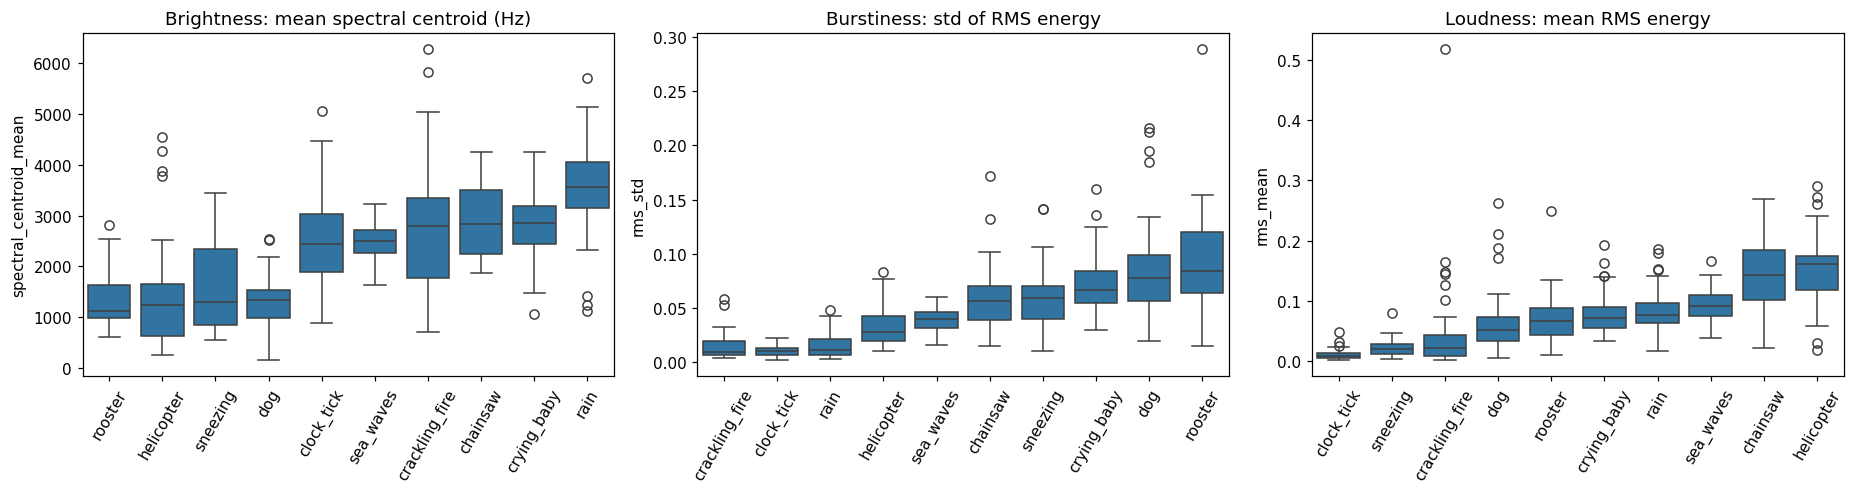

                spectral_centroid_mean  rms_std  rms_mean
label                                                    
dog                           1301.985    0.086     0.064
rooster                       1349.989    0.093     0.070
helicopter                    1450.350    0.033     0.155
sneezing                      1576.582    0.060     0.022
sea_waves                     2484.896    0.039     0.095
clock_tick                    2527.206    0.011     0.011
crying_baby                   2767.613    0.074     0.082
crackling_fire                2784.312    0.016     0.050
chainsaw                      2909.443    0.060     0.144
rain                          3536.599    0.016     0.085


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for a, (f, t) in zip(ax, [("spectral_centroid_mean","Brightness: mean spectral centroid (Hz)"),
                          ("rms_std","Burstiness: std of RMS energy"),
                          ("rms_mean","Loudness: mean RMS energy")]):
    order = df.groupby("label")[f].median().sort_values().index
    sns.boxplot(data=df, x="label", y=f, order=order, ax=a); a.set_title(t); a.tick_params(axis="x", rotation=60); a.set_xlabel("")
plt.tight_layout(); plt.show()
print(df.groupby("label")[["spectral_centroid_mean","rms_std","rms_mean"]].mean().round(3).sort_values("spectral_centroid_mean"))

**Interpretations**

1. **Spectral centroid (brightness).** Rain is the brightest sound (~3.5 kHz) while dog, rooster, sneezing and helicopter sit at ~1.3-1.6 kHz. Noise-like sounds (rain, chainsaw, crying baby) spread energy into high frequencies; barks, crows and rotor thumps are low and tonal. This one feature alone splits the classes into a "dark" and a "bright" group.
2. **RMS standard deviation (burstiness).** Clock tick, crackling fire and rain are steady (about 0.011-0.016), but dog and rooster vary 5-8x more (about 0.087-0.093) because the sound appears and disappears inside the clip. It separates continuous sounds from event-like ones, even when their pitch is similar.
3. **RMS mean (loudness).** Helicopter and chainsaw are the loudest (~0.15) and clock tick and sneezing are the quietest (~0.01-0.02). Combined with brightness it separates helicopter (loud, dark) from dog (quiet, dark).

*Caveat:* spectral flatness is highest for sneezing and rooster. That is largely an artefact: ESC clips are padded with digital silence, and silent frames look "flat", so the feature partly measures how short the event is.

## 4. Model creation
Three candidates are compared. Train = folds 1-4, test = fold 5 (never used for training), plus 5-fold cross-validation over the predefined folds as a robustness check.

In [10]:
X, y, fold = df[FEATURE_NAMES], df.label, df.fold
cands = {
  "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=3000)),
  "Random Forest":       RandomForestClassifier(400, random_state=0),
  "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=0)),
}
rows = []
for n, m in cands.items():
    m.fit(X[fold != 5], y[fold != 5]); p = m.predict(X[fold == 5]); pr = m.predict_proba(X[fold == 5])
    cv = np.mean([accuracy_score(y[fold == k], m.fit(X[fold != k], y[fold != k]).predict(X[fold == k])) for k in range(1, 6)])
    rows.append(dict(model=n, test_accuracy=accuracy_score(y[fold==5], p), test_f1_macro=f1_score(y[fold==5], p, average="macro"),
                     test_log_loss=log_loss(y[fold==5], pr, labels=m.classes_), cv_accuracy_5fold=cv))
cmp_ = pd.DataFrame(rows).set_index("model").round(3); display(cmp_)

,test_accuracy,test_f1_macro,test_log_loss,cv_accuracy_5fold
model,,,,
Logistic Regression,0.762,0.753,0.929,0.755
Random Forest,0.800,0.799,0.765,0.798
SVM (RBF),0.825,0.822,0.728,0.838


The RBF-SVM has the best accuracy, F1 and log loss on the hold-out fold, so it is the deployed model (a Random Forest is a close second).

## 5. Model testing: full metrics on the hold-out fold
This uses the same `src.train.train()` function that the API calls for (re)training.

{'accuracy': 0.825, 'precision_macro': 0.845, 'recall_macro': 0.825, 'f1_macro': 0.8216, 'log_loss': 0.7277} | train/test: 320 80
Majority-class baseline accuracy: 0.100 (10 balanced classes)
ROC-AUC (macro, one-vs-rest): 0.9783


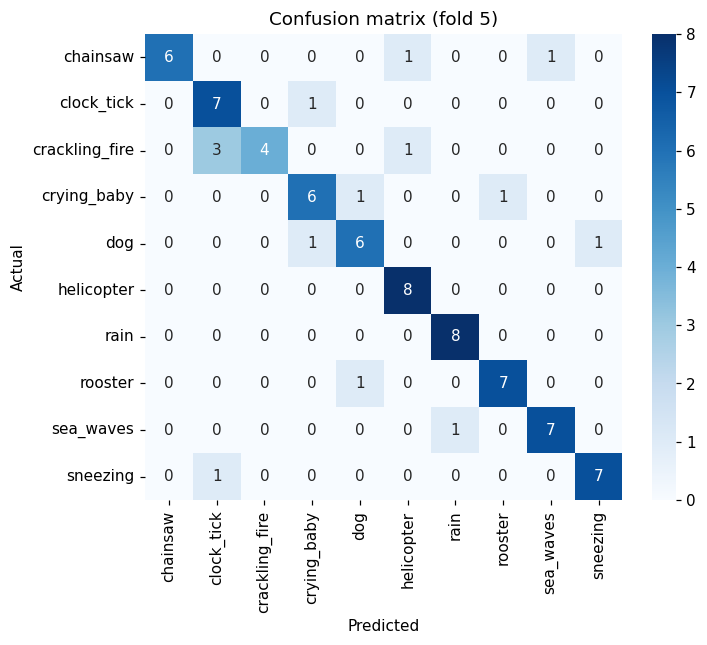

                precision    recall  f1-score   support

      chainsaw       1.00      0.75      0.86         8
    clock_tick       0.64      0.88      0.74         8
crackling_fire       1.00      0.50      0.67         8
   crying_baby       0.75      0.75      0.75         8
           dog       0.75      0.75      0.75         8
    helicopter       0.80      1.00      0.89         8
          rain       0.89      1.00      0.94         8
       rooster       0.88      0.88      0.88         8
     sea_waves       0.88      0.88      0.88         8
      sneezing       0.88      0.88      0.88         8

      accuracy                           0.82        80
     macro avg       0.85      0.82      0.82        80
  weighted avg       0.85      0.82      0.82        80



In [11]:
m1 = T.train(trigger="notebook")
print({k: round(m1[k], 4) for k in ["accuracy","precision_macro","recall_macro","f1_macro","log_loss"]}, "| train/test:", m1["n_train"], m1["n_test"])
print("Majority-class baseline accuracy: 0.100 (10 balanced classes)")
b = pickle.load(open(T.MODEL_PATH, "rb")); test = df[df.fold == 5]
proba = b["pipeline"].predict_proba(test[FEATURE_NAMES])
print("ROC-AUC (macro, one-vs-rest):", round(roc_auc_score(test.label, proba, multi_class="ovr", labels=b["pipeline"].classes_), 4))
cm = np.array(m1["confusion_matrix"])
plt.figure(figsize=(7, 5.5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=m1["classes"], yticklabels=m1["classes"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix (fold 5)"); plt.show()
print(classification_report(test.label, b["pipeline"].predict(test[FEATURE_NAMES]), zero_division=0))

## 5b. Prediction functions
Reusable functions that load the saved model file (`model.pkl`) and predict from a sound. The API's `/api/predict` endpoint uses the same logic.

In [12]:
_model_cache = {}
def load_model(path=None):
    path = str(path or T.MODEL_PATH)
    if path not in _model_cache:
        with open(path, "rb") as f:
            _model_cache[path] = pickle.load(f)          # dict: pipeline + feature order + version
    return _model_cache[path]

def predict_file(source, top_k=3, model_path=None):
    """Predict the sound class of ONE clip. source = path, raw bytes or file-like object (.wav).
    Returns {'prediction', 'confidence', 'top_k': [(label, prob), ...], 'model_version'}."""
    b = load_model(model_path)
    feats = extract_features(load_audio(source))                    # same preprocessing as training
    proba = b["pipeline"].predict_proba(pd.DataFrame([feats])[b["features"]])[0]
    order = proba.argsort()[::-1][:top_k]
    classes = b["pipeline"].classes_
    return {"prediction": str(classes[order[0]]), "confidence": round(float(proba[order[0]]), 3),
            "top_k": [(str(classes[i]), round(float(proba[i]), 3)) for i in order], "model_version": b["version"]}

def predict_batch(paths, model_path=None):
    """Predict many clips; returns a DataFrame with one row per file."""
    return pd.DataFrame([{"file": Path(p).name, **{k: v for k, v in predict_file(p, model_path=model_path).items() if k in ("prediction", "confidence")}} for p in paths])

# single-clip prediction
fn = meta[(meta.category == "rain") & (meta.fold == 5)].filename.iloc[0]
print("Actual: rain ->", predict_file(ESC_DIR / "audio" / fn))

Actual: rain -> {'prediction': 'rain', 'confidence': 0.918, 'top_k': [('rain', 0.918), ('sea_waves', 0.048), ('clock_tick', 0.01)], 'model_version': 1}


In [13]:
# batch prediction on a few held-out clips (one per class), with a correctness check
sample = meta[meta.fold == 5].groupby("category").head(1)
res_ = predict_batch([ESC_DIR / "audio" / f for f in sample.filename])
res_["actual"] = sample.category.values; res_["correct"] = res_.prediction == res_.actual
display(res_); print("Correct:", int(res_.correct.sum()), "/", len(res_))

,file,prediction,confidence,actual,correct
0,5-151085-A-20.wav,crying_baby,0.881,crying_baby,True
1,5-170338-A-41.wav,chainsaw,0.419,chainsaw,True
2,5-177957-A-40.wav,rain,0.241,helicopter,False
3,5-181766-A-10.wav,rain,0.918,rain,True
4,5-186924-A-12.wav,helicopter,0.216,crackling_fire,False
5,5-187979-A-21.wav,sneezing,0.907,sneezing,True
6,5-194930-A-1.wav,dog,0.669,rooster,False
7,5-200461-A-11.wav,sea_waves,0.877,sea_waves,True
8,5-201194-A-38.wav,clock_tick,0.538,clock_tick,True
9,5-203128-A-0.wav,dog,0.816,dog,True


Correct: 7 / 10


### Model file check
The trained model is saved as a standard Python pickle (`models/model.pkl`). The cell below loads the copy stored in the repository (created by `python -m src.train`) and confirms it reproduces the hold-out accuracy.

In [14]:
repo_model = ROOT / "models" / "model.pkl"
print("Repository model file:", repo_model, "|", f"{repo_model.stat().st_size/1024:.0f} KB" if repo_model.exists() else "not found (run python -m src.train)")
if repo_model.exists():
    b = load_model(repo_model); test = df[df.fold == 5]
    acc = accuracy_score(test.label, b["pipeline"].predict(test[b["features"]]))
    print("Loaded pickle ->", type(b["pipeline"]).__name__, "with", len(b["features"]), "features | hold-out accuracy:", round(acc, 3))

Repository model file: /home/claude/proj/models/model.pkl | 95 KB
Loaded pickle -> Pipeline with 34 features | hold-out accuracy: 0.825


## 6. Retraining and its trigger
Retraining is a single function (`src.train.run_retrain_job`) that rebuilds the model from the base data **plus every uploaded clip**, re-evaluates it on the same hold-out fold, saves it atomically and logs a new version. It can be triggered three ways:
* the **Retrain** button in the dashboard (`POST /api/retrain`, also usable from a scheduler or webhook),
* **automatically** when the number of newly uploaded clips reaches `AUTO_RETRAIN_THRESHOLD` (20 by default),
* from the command line: `python -m src.train`.

Demo: upload 24 new labelled clips through the real API (augmented copies: pitch-shifted dog and rain clips from folds 1-4), let the threshold trigger retraining, and compare versions.

In [15]:
from fastapi.testclient import TestClient
from api.main import app
client = TestClient(app).__enter__()
rng = np.random.default_rng(0)
tmp = WORK / "new_clips"; tmp.mkdir()
for c in ["dog", "rain"]:
    for fn in meta[(meta.category == c) & (meta.fold < 5)].filename.iloc[:12]:
        y = librosa.effects.pitch_shift(load_audio(ESC_DIR/"audio"/fn), sr=SR, n_steps=2) + rng.normal(0, 0.003, 5*SR)
        sf.write(tmp / f"{c}_{fn}", y, SR)
for c in ["dog", "rain"]:
    files = [("files", (p.name, open(p, "rb"), "audio/wav")) for p in sorted(tmp.glob(f"{c}_*.wav"))]
    r = client.post("/api/upload", data={"label": c}, files=files).json()
    print(c, "->", {k: r[k] for k in ["accepted","pending_uploads","auto_retrain_started"]})
for _ in range(60):
    st = client.get("/api/retrain/status").json()
    if st["state"] in ("done", "failed"): break
    time.sleep(1)
print(st["state"], "-", st["message"])
display(pd.DataFrame(client.get("/api/metrics").json()["history"]).round(3))

dog -> {'accepted': 12, 'pending_uploads': 12, 'auto_retrain_started': False}


rain -> {'accepted': 12, 'pending_uploads': 24, 'auto_retrain_started': True}
done - Model v2 trained: accuracy 0.812, F1 0.812


,version,trained_at,trigger,n_train,n_uploads_used,accuracy,f1_macro,log_loss,train_seconds
0,1,2026-11-25T22:12:10+00:00,notebook,320,0,0.825,0.822,0.728,0.04
1,2,2026-11-25T22:12:13+00:00,auto: upload threshold,344,24,0.812,0.812,0.741,0.05


Version 2 was created automatically when the 20-clip threshold was crossed. Because the hold-out fold never changes, the rows are directly comparable. The demo clips are augmented copies of existing recordings, so no real improvement is expected: a difference of one or two clips out of 80 is just noise. The point is that the whole loop (upload, threshold trigger, retrain, re-evaluate, new version) works; with genuinely new recordings the same mechanism lets the model adapt, including to brand-new classes.

## 7. Evaluating the model "in production" (through the API)
Every hold-out clip is sent to `/api/predict` over HTTP, exactly as a client would, and we measure accuracy and latency. Set `BASE_URL` to the deployed Render URL to run the same evaluation against production.

In [16]:
import requests
BASE_URL = os.getenv("BASE_URL")           # e.g. https://esc10-sound-classifier.onrender.com ; None -> in-process test client
test_files = meta[meta.fold == 5]
res = []
for r in test_files.itertuples():
    data = (ESC_DIR / "audio" / r.filename).read_bytes()
    t0 = time.perf_counter()
    if BASE_URL: out = requests.post(BASE_URL + "/api/predict", files={"file": ("c.wav", data)}).json()
    else:        out = client.post("/api/predict", files={"file": ("c.wav", data)}).json()
    res.append(dict(actual=r.category, pred=out["prediction"], conf=out["confidence"], ms=(time.perf_counter()-t0)*1000))
res = pd.DataFrame(res)
print(f"API accuracy: {(res.actual == res.pred).mean():.3f} | mean confidence: {res.conf.mean():.2f}")
print(f"Latency ms: p50={res.ms.quantile(.5):.0f}  p95={res.ms.quantile(.95):.0f}  max={res.ms.max():.0f}")
print("Confidence when right vs wrong:", res.assign(ok=res.actual==res.pred).groupby("ok").conf.mean().round(2).to_dict())

API accuracy: 0.812 | mean confidence: 0.65
Latency ms: p50=62  p95=70  max=83
Confidence when right vs wrong: {False: 0.47, True: 0.69}


## 8. Conclusions
* The RBF-SVM on 34 audio summary features reaches roughly **80%+ accuracy** (random guessing: 10%) on unseen recordings, and confidence is higher on correct predictions than on wrong ones.
* Errors concentrate in acoustically similar classes (see the confusion matrix); richer features (log-mel spectrogram CNN) or more data would be the next step.
* Retraining is automated, versioned and comparable across versions; the load test (Locust) and deployment results are documented in the README.